Si cuantizamos a 4 niveles, cada píxel/Canal solo podrá tomar uno de esos 4 valores (por ejemplo: 0, 85, 170, 255). 64 colores posibles 4^3
Si cuantizamos a 2 niveles solo podrán haber 8 colores 2^3

In [12]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [13]:
# Subir imagen
uploaded = files.upload()
image_path = list(uploaded.keys())[0] # Toma el nombre (ruta) del archivo que se carga en almacenamiento local de colab

Saving peppers.png to peppers (1).png


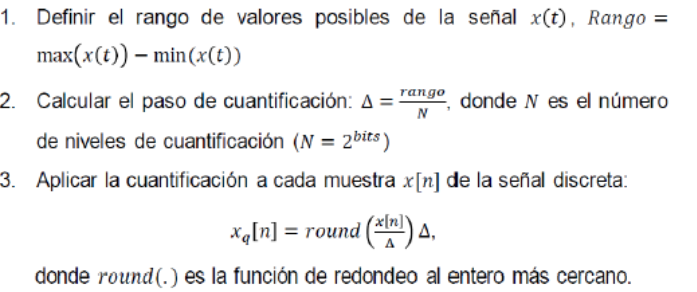

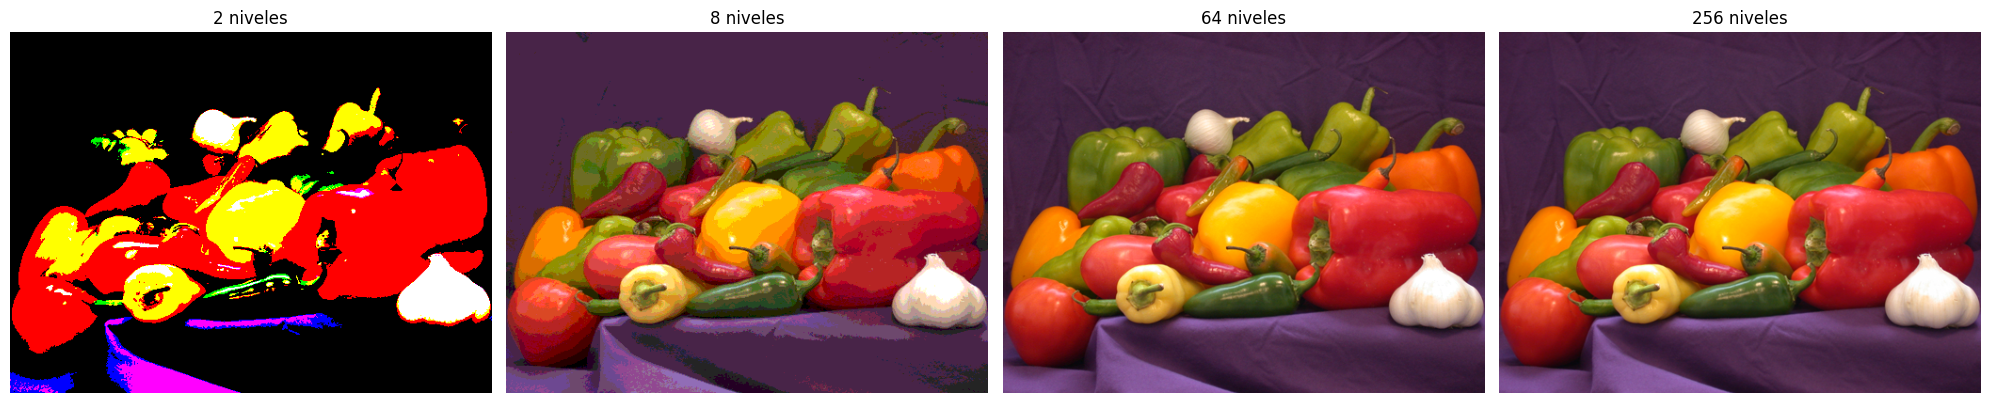

In [7]:
# Cargar imagen en COLOR: OpenCV usa BGR!!!
img = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convertimos a RGB (orden que espera matplotlib)
img_np = np.array(img_rgb)

# Función de cuantificación por canal
def cuantizar_imagen(imagen, niveles):
    # Convertir a float para evitar errores por truncamiento
    img_float = imagen #.astype(np.float32)

    # Cuantización uniforme: mapea a niveles discretos (Normaliza, Escala, redondea y expande)
    cuantizada = np.round((img_float / 255.0) * (niveles - 1)) * (255.0 / (niveles - 1))
    cuantizada = np.clip(cuantizada, 0, 255).astype(np.uint8)
    return cuantizada

# Niveles de cuantificación a probar
levels_list = [2, 8, 64, 256]

# Mostrar imágenes cuantificadas
plt.figure(figsize=(20, 12))
for i, level in enumerate(levels_list):
    quantized_img =  cuantizar_imagen(img_np, level) #cuantizar_imagen(img_np, level)
    plt.subplot(1, len(levels_list), i + 1)
    plt.imshow(quantized_img)
    plt.title(f"{level} niveles")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
# Aplanar los píxeles a una matriz de N x 3 (en cada fila = un color)
pixeles = cuantizar_imagen(img_np, 2).reshape(-1, 3)
# Obtener filas únicas (colores únicos)
colores_unicos = np.unique(pixeles, axis=0)
print(colores_unicos)

[[  0   0   0]
 [  0   0 255]
 [  0 255   0]
 [  0 255 255]
 [255   0   0]
 [255   0 255]
 [255 255   0]
 [255 255 255]]


[0, 0, 0] = Negro

[0, 0, 255] = Azul

[0, 255, 0] = Verde

[0, 255, 255] = Cian (Turquesa)

[255, 0, 0] = Rojo

[255, 0, 255] = Magenta (Fucsia)

[255, 255, 0] = Amarillo

[255, 255, 255] = Blanco

2
8
255
247.0
[[  8   8   8]
 [  8   8 255]
 [  8 255   8]
 [  8 255 255]
 [255   8   8]
 [255   8 255]
 [255 255   8]
 [255 255 255]]


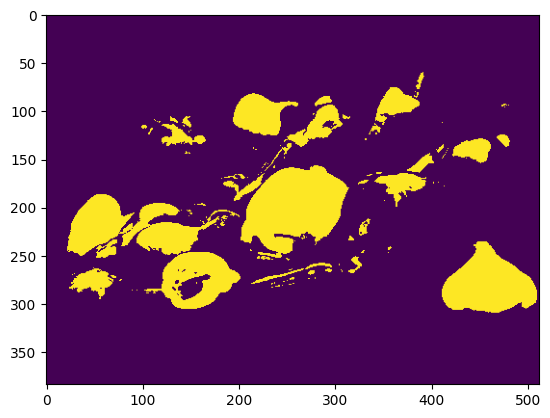

In [9]:
# Cargar imagen en COLOR: OpenCV usa BGR!!!
img = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # Convertimos a RGB (orden que espera matplotlib) | a grises cv2.COLOR_BGR2GRAY
img_np = np.array(img_rgb)


bits = 1
N=2**bits # niveles de cuantificación por canal
print(N)
xmin = img_np.min()
print(xmin)
xmax = img_np.max()
print(xmax)
dS = (xmax - xmin)/(N-1)  # ΔS
print(dS)
xq = xmin + np.rint((img_np - xmin) / dS) * dS # redondea al entero más cercano
xq = np.clip(xq, 0, 255).astype(np.uint8)
plt.imshow(xq)
# Aplanar los píxeles a una matriz de N x 3 (en cada fila = un color)
pixeles = xq.reshape(-1, 3)
# Obtener filas únicas (colores únicos)
colores_unicos = np.unique(pixeles, axis=0)
print(colores_unicos)

np.rint redondea los elementos de un array al número entero más cercano

Niveles: 8
xmin=7, xmax=255
ΔS=35.42857142857143


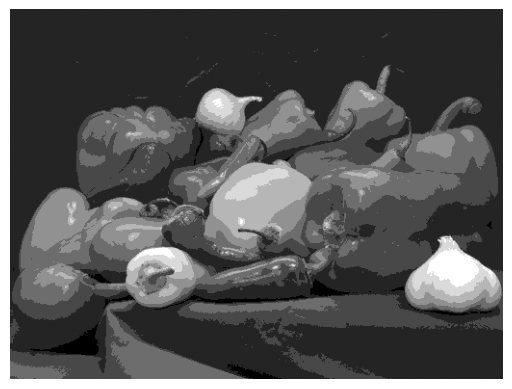

Niveles únicos: [  7  42  77 113 148 184 219 255]


In [10]:
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
img_np = np.array(img)

# --- Cuantización ---
bits = 3
N = 2 ** bits
print(f"Niveles: {N}")

xmin = img_np.min()
xmax = img_np.max()
print(f"xmin={xmin}, xmax={xmax}")

dS = (xmax - xmin) / (N - 1)
print(f"ΔS={dS}")

xq = xmin + np.rint((img_np - xmin) / dS) * dS
xq = np.clip(xq, 0, 255).astype(np.uint8)

# --- Mostrar resultado ---
plt.imshow(xq, cmap='gray')
plt.axis('off')
plt.show()

# --- Colores (niveles) únicos ---
pixeles = xq.reshape(-1)
niveles_unicos = np.unique(pixeles)
print("Niveles únicos:", niveles_unicos)


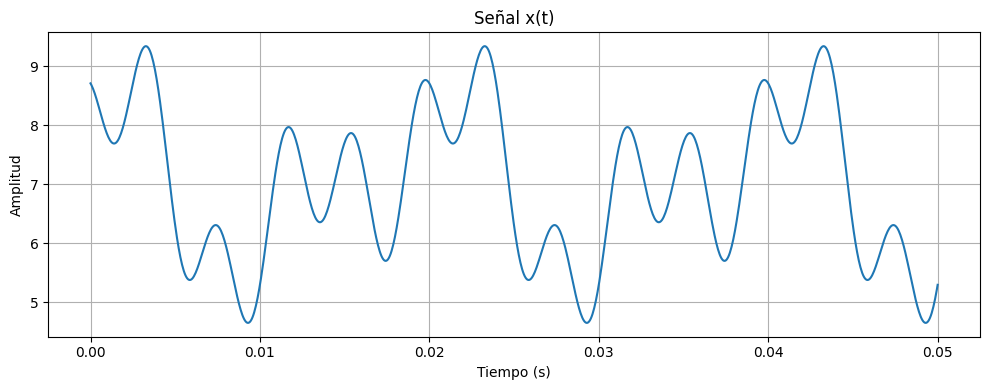

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Definir el tiempo
t = np.linspace(0, 0.05, 1000)  # desde 0 hasta 0.05 segundos

# Definir la señal
x = np.cos(100 * np.pi * t) + np.sin(200 * np.pi * t) + np.cos(500 * np.pi * t + np.pi / 4) + 7

# Graficar la señal
plt.figure(figsize=(10, 4))
plt.plot(t, x)
plt.title('Señal x(t)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.tight_layout()
plt.show()